# Прокат велосипедов в Сеуле

Разведочный анализ [Seoul Bike Sharing Demand (UCI)](https://archive.ics.uci.edu/dataset/560/seoul%2Bbike%2Bsharing%2Bdemand) для лабораторной № 4.
Одна строка соответствует одному часу. Изучим качество данных, работу проката, распределение числа аренд и различия по времени и погоде.

Для повторного запуска нужен `SeoulBikeData.csv` рядом с ноутбуком. Зависимости Python: `pandas` и `matplotlib`.

In [28]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import networkx as nx
import pyagrum as gum
from IPython.display import display

csv_path = Path("SeoulBikeData.csv")
raw = pd.read_csv(csv_path, encoding="cp1252")
rentals = "Rented Bike Count"
temperature = "Temperature(°C)"
operating = "Functioning Day"

print(f"{len(raw):,} строк, {raw.shape[1]} столбцов")
display(raw.head(15))

8,760 строк, 14 столбцов


,Date,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day
0,01/12/2017,254,0,-5.2,37,2.2,2000,-17.6,0.00,0.0,0.0,Winter,No Holiday,Yes
1,01/12/2017,204,1,-5.5,38,0.8,2000,-17.6,0.00,0.0,0.0,Winter,No Holiday,Yes
2,01/12/2017,173,2,-6.0,39,1.0,2000,-17.7,0.00,0.0,0.0,Winter,No Holiday,Yes
3,01/12/2017,107,3,-6.2,40,0.9,2000,-17.6,0.00,0.0,0.0,Winter,No Holiday,Yes
4,01/12/2017,78,4,-6.0,36,2.3,2000,-18.6,0.00,0.0,0.0,Winter,No Holiday,Yes
5,01/12/2017,100,5,-6.4,37,1.5,2000,-18.7,0.00,0.0,0.0,Winter,No Holiday,Yes
6,01/12/2017,181,6,-6.6,35,1.3,2000,-19.5,0.00,0.0,0.0,Winter,No Holiday,Yes
7,01/12/2017,460,7,-7.4,38,0.9,2000,-19.3,0.00,0.0,0.0,Winter,No Holiday,Yes
8,01/12/2017,930,8,-7.6,37,1.1,2000,-19.8,0.01,0.0,0.0,Winter,No Holiday,Yes
9,01/12/2017,490,9,-6.5,27,0.5,1928,-22.4,0.23,0.0,0.0,Winter,No Holiday,Yes


## Качество и состав данных

Календарные признаки — дата, час, сезон и праздник. `Functioning Day` обозначает доступность проката.
Погодные измерения включают температуру воздуха и точки росы, влажность, ветер, видимость,
солнечную радиацию, дождь и снег. `Rented Bike Count` — число аренд за час.

In [29]:
timestamp = pd.to_datetime(raw["Date"], format="%d/%m/%Y") + pd.to_timedelta(raw["Hour"], unit="h")
expected_hours = pd.date_range(timestamp.min(), timestamp.max(), freq="h")
missing_hours = expected_hours.difference(pd.DatetimeIndex(timestamp))

quality = pd.Series({
    "Начало периода": timestamp.min(),
    "Конец периода": timestamp.max(),
    "Пропущенные значения": int(raw.isna().sum().sum()),
    "Полные дубли строк": int(raw.duplicated().sum()),
    "Повторяющиеся дата и час": int(timestamp.duplicated().sum()),
    "Отсутствующие часы в периоде": len(missing_hours),
    "Некорректные значения часа": int((~raw["Hour"].between(0, 23)).sum()),
    "Отрицательное число аренд": int(raw[rentals].lt(0).sum()),
}, name="Результат")
display(quality.to_frame())

,Результат
Начало периода,2017-12-01 00:00:00
Конец периода,2018-11-30 23:00:00
Пропущенные значения,0
Полные дубли строк,0
Повторяющиеся дата и час,0
Отсутствующие часы в периоде,0
Некорректные значения часа,0
Отрицательное число аренд,0


## Часы, когда прокат работал

Сначала сравним число аренд по статусу проката. Для анализа спроса дальше оставим только часы с `Functioning Day = Yes`.
Так нули в часы закрытия не попадут в одну группу с низким прокатом во время работы.

In [30]:
by_status = raw.groupby(operating)[rentals].agg(
    часов="size", минимум="min", медиана="median", максимум="max"
)
display(by_status)

open_hours = raw.loc[raw[operating].eq("Yes")].copy()
open_hours["Дождь"] = open_hours["Rainfall(mm)"].gt(0).map({True: "Да", False: "Нет"})
periods = ["Ночь", "Утро", "День", "Вечер"]
open_hours["Время суток"] = pd.cut(
    open_hours["Hour"], bins=[-1, 5, 11, 17, 23], labels=periods
)
print(f"Для анализа осталось {len(open_hours):,} часов.")

,часов,минимум,медиана,максимум
Functioning Day,,,,
No,295,0,0.0,0
Yes,8465,2,542.0,3556


Для анализа осталось 8,465 часов.


## Распределение аренд и время суток

Гистограмма показывает, как часто встречается разное число аренд. На почасовом графике сплошная линия —
медиана, а полоса — интервал от 25-го до 75-го процентиля. В этом интервале лежит средняя половина наблюдений каждого часа.

,Аренд в час
count,8465.0
mean,729.2
std,642.4
min,2.0
25%,214.0
50%,542.0
75%,1084.0
max,3556.0


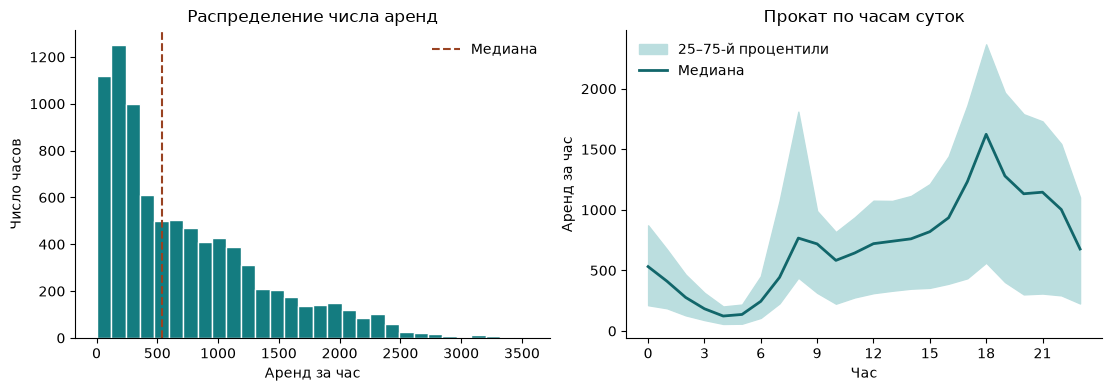

Наибольшая почасовая медиана: 1624 аренд в 18:00.


In [31]:
distribution = open_hours[rentals].describe(percentiles=[.25, .5, .75])
display(distribution.round(1).to_frame("Аренд в час"))

by_hour = (
    open_hours.groupby("Hour")[rentals]
    .quantile([.25, .5, .75])
    .unstack()
    .rename(columns={.25: "q25", .5: "median", .75: "q75"})
)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), layout="constrained")
axes[0].hist(open_hours[rentals], bins=30, color="#147C80", edgecolor="white")
axes[0].axvline(distribution["50%"], color="#994221", linestyle="--", label="Медиана")
axes[0].set(title="Распределение числа аренд", xlabel="Аренд за час", ylabel="Число часов")
axes[0].legend(frameon=False)
axes[1].fill_between(by_hour.index, by_hour["q25"], by_hour["q75"], color="#BBDEDF", label="25–75-й процентили")
axes[1].plot(by_hour.index, by_hour["median"], color="#11666A", linewidth=2, label="Медиана")
axes[1].set(title="Прокат по часам суток", xlabel="Час", ylabel="Аренд за час", xticks=range(0, 24, 3))
axes[1].legend(frameon=False)
for ax in axes:
    ax.spines[["right", "top"]].set_visible(False)
plt.show()
print(f"Наибольшая почасовая медиана: {by_hour['median'].max():.0f} аренд в {by_hour['median'].idxmax():02d}:00.")

## Дождь, температура и сезон

Дождём считаем час, когда в `Rainfall(mm)` записано значение больше нуля. Сравним медианы в сухие и дождливые часы,
в том числе отдельно для четырёх частей суток: ночь 00–05, утро 06–11, день 12–17 и вечер 18–23.
Число часов в каждой группе показывает, на каком объёме данных основано сравнение.

,часов,медиана
Дождь,,
Нет,7949,591.0
Да,516,71.0


часов       медиана        
Дождь          Да   Нет      Да     Нет
Время суток                            
Ночь          141  1971    65.0   224.0
Утро          143  1974    60.0   592.0
День          106  2012    70.5   898.0
Вечер         126  1992    74.5  1113.0

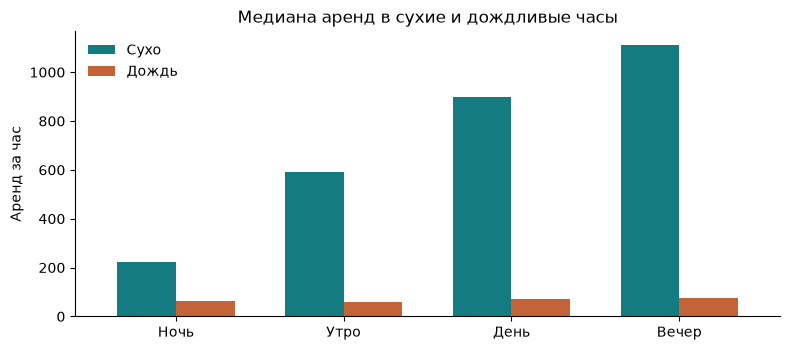

In [32]:
rain_summary = open_hours.groupby("Дождь")[rentals].agg(часов="size", медиана="median")
display(rain_summary.reindex(["Нет", "Да"]))

rain_by_period = (
    open_hours.groupby(["Время суток", "Дождь"], observed=True)[rentals]
    .agg(часов="size", медиана="median")
    .unstack("Дождь")
)
display(rain_by_period)

ax = rain_by_period["медиана"][["Нет", "Да"]].plot.bar(
    color=["#147C80", "#C56338"], figsize=(8, 3.6), rot=0, width=.7
)
ax.set(title="Медиана аренд в сухие и дождливые часы", xlabel="", ylabel="Аренд за час")
ax.legend(["Сухо", "Дождь"], frameon=False)
ax.spines[["right", "top"]].set_visible(False)
plt.tight_layout()
plt.show()

In [33]:
by_season = open_hours.groupby("Seasons").agg(
    часов=(rentals, "size"),
    медиана_аренд=(rentals, "median"),
    медиана_температуры=(temperature, "median"),
)
display(by_season.rename(index={
    "Winter": "Зима", "Spring": "Весна", "Summer": "Лето", "Autumn": "Осень"
}))

,часов,медиана_аренд,медиана_температуры
Seasons,,,
Осень,1937,856.0,13.3
Весна,2160,599.0,13.3
Лето,2208,905.5,26.6
Зима,2160,203.0,-2.2


В рабочих часах медиана составляла **591 аренду без дождя** и **71 при дожде**. Разница сохраняется при сравнении
внутри каждой из четырёх частей суток. Это наблюдаемая связь. Температура, сезон и другие условия тоже могут различаться
между группами. Сезонные медианы температуры и аренд в таблице показывают, почему полезно учитывать сезон при сравнении.

## Пробная группировка для обсуждения

Для будущего этапа можно рассмотреть три уровня проката по 33-му и 67-му процентилям. Такие границы дают группы
примерно одинакового размера. Температуру для пробы разделим по понятным порогам 10 и 20 °C.
Проверим, сколько часов есть в сочетаниях температуры, дождя и времени суток.

In [34]:
low_cut, high_cut = open_hours[rentals].quantile([1 / 3, 2 / 3], interpolation="nearest")
rental_level = pd.cut(
    open_hours[rentals],
    bins=[-float("inf"), low_cut, high_cut, float("inf")],
    labels=[f"≤ {low_cut}", f"{low_cut + 1}–{high_cut}", f"> {high_cut}"],
)
temperature_band = pd.cut(
    open_hours[temperature],
    bins=[-float("inf"), 10, 20, float("inf")],
    labels=["≤ 10", "(10, 20]", "> 20"],
)
grouped = open_hours.assign(Температура=temperature_band)
coverage = (
    grouped.groupby(["Время суток", "Температура", "Дождь"], observed=False)
    .size()
    .unstack("Дождь")
    .reindex(columns=["Нет", "Да"])
)

display(rental_level.value_counts(sort=False).to_frame("Часов по уровню проката"))
display(grouped.groupby("Температура", observed=True)[rentals].agg(часов="size", медиана_аренд="median"))
display(coverage)
print(f"Минимум в одной комбинации: {coverage.min().min()} часов.")

,Часов по уровню проката
Rented Bike Count,
≤ 285,2826
286–895,2819
> 895,2820


,часов,медиана_аренд
Температура,,
≤ 10,3571,243.0
"(10, 20]",2058,792.0
> 20,2836,1048.0


Дождь                    Нет  Да
Время суток Температура         
Ночь        ≤ 10         995  36
            (10, 20]     503  47
            > 20         473  58
Утро        ≤ 10         933  38
            (10, 20]     469  54
            > 20         572  51
День        ≤ 10         689  20
            (10, 20]     436  36
            > 20         887  50
Вечер       ≤ 10         836  24
            (10, 20]     478  35
            > 20         678  67

Минимум в одной комбинации: 20 часов.


В пробном разбиении все комбинации представлены, но отдельные группы малы. Например, прохладных дождливых
часов с 12:00 по 17:59 всего 20. Если добавить ещё категории, некоторые комбинации могут стать совсем редкими.
Наблюдения охватывают один год и идут подряд, поэтому соседние часы могут быть похожи.

## Вопросы для вероятностного вывода

Все запросы относятся к часам, когда прокат работал. Переменная запроса $Y$ — уровень проката за час: **низкий** (до 285 аренд включительно), **средний** (286–895) или **высокий** (больше 895). В каждом сравнении рассматриваем вероятности всех трёх уровней.

1. **Как меняется распределение уровня проката в дождливые часы?** Сравним $P(Y)$ и $P(Y\mid \text{дождь})$. Дождливым считаем час с `Rainfall(mm) > 0`. Дополнительно можно сравнить с сухими часами.
2. **Как меняется распределение уровня проката днём, если идёт снег?** Сравним $P(Y\mid \text{день})$ и $P(Y\mid \text{день},\text{снегопад})$. День — часы с 12:00 до 17:59, снегопад — `Snowfall (cm) > 0`.
3. **Как уровень солнечной радиации связан с уровнем проката днём?** Сравним дневное распределение $P(Y\mid \text{день})$ с $P(Y\mid \text{день},\text{уровень радиации})$ для низкого, среднего и высокого уровней. Пробные границы — 0,95 и 1,97 МДж/м², примерно 33-й и 67-й процентили дневных наблюдений.

Формулировки описывают сравнение наблюдаемых условий. Направления рёбер сети обсудим отдельно.

## Согласованные рёбра графа

- Время суток → солнечная радиация. Положение Солнца меняется в течение суток.
- Дождь → солнечная радиация. Дождь служит наблюдаемым признаком облачности, с которой связано ослабление излучения.
- Время суток → уровень проката. Частота поездок различается между частями суток при сопоставимых категориях погоды.
- Дождь → уровень проката. При сопоставимых дневных условиях в дождливые часы чаще наблюдается низкий прокат.
- Снегопад → уровень проката. В сопоставимых зимних дневных часах со снегопадом чаще наблюдается низкий прокат.
- Солнечная радиация → уровень проката. Среди дневных часов без осадков доля высокого проката различается между уровнями радиации.

Стрелки задают условные зависимости модели. Пусть $T$ — время суток, $D$ — дождь, $S$ — снегопад, $R$ — уровень радиации, а $Y$ — уровень проката. Тогда факторизация имеет вид

$$
P(T,D,S,R,Y) = P(T)P(D)P(S)P(R\mid T,D)P(Y\mid T,D,S,R).
$$

Граф задаём через `networkx.DiGraph`. Каждая пара в списке рёбер записана в порядке `(родитель, дочерний узел)`.

In [35]:
edges = [
    ("Время суток", "Радиация"),
    ("Дождь", "Радиация"),
    ("Время суток", "Уровень проката"),
    ("Дождь", "Уровень проката"),
    ("Снегопад", "Уровень проката"),
    ("Радиация", "Уровень проката"),
]

dag = nx.DiGraph()
dag.add_edges_from(edges)
if not nx.is_directed_acyclic_graph(dag):
    raise ValueError("В графе найден направленный цикл.")

print(f"DAG: {dag.number_of_nodes()} узлов, {dag.number_of_edges()} рёбер.")
print("Родители уровня проката:", ", ".join(dag.predecessors("Уровень проката")))

DAG: 5 узлов, 6 рёбер.
Родители уровня проката: Время суток, Дождь, Снегопад, Радиация


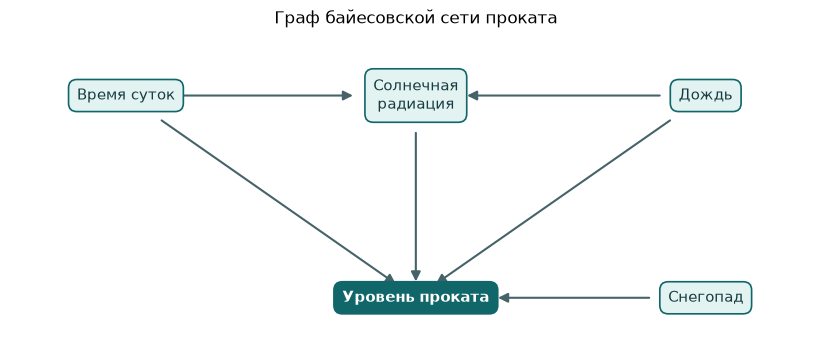

In [36]:
positions = {
    "Время суток": (-2.25, 1.25),
    "Радиация": (0, 1.25),
    "Дождь": (2.25, 1.25),
    "Снегопад": (2.25, -0.65),
    "Уровень проката": (0, -0.65),
}
labels = {"Радиация": "Солнечная\nрадиация"}

fig, ax = plt.subplots(figsize=(8.2, 3.5), layout="constrained")
ax.set(xlim=(-3.15, 3.15), ylim=(-1.15, 1.85), title="Граф байесовской сети проката")
ax.set_axis_off()

boxes = {}
for node, (x, y) in positions.items():
    is_target = node == "Уровень проката"
    label = ax.text(
        x, y, labels.get(node, node), ha="center", va="center", fontsize=11,
        color="white" if is_target else "#163C41",
        fontweight="bold" if is_target else "normal", zorder=3,
        bbox={"boxstyle": "round,pad=0.55", "fc": "#11666A" if is_target else "#E3F3F2",
              "ec": "#11666A", "lw": 1.2},
    )
    boxes[node] = label.get_bbox_patch()

for parent, child in dag.edges:
    ax.annotate(
        "", xy=positions[child], xytext=positions[parent],
        arrowprops={"arrowstyle": "-|>", "color": "#466369", "lw": 1.5,
                    "mutation_scale": 14, "shrinkA": 3, "shrinkB": 4,
                    "patchA": boxes[parent], "patchB": boxes[child]},
        zorder=2,
    )

plt.show()

## Наблюдения для таблицы таргета

Для каждой комбинации родителей $Y$ считаем количество часов $n$ и делим число часов каждого класса на $n$.
При $n=0$ эмпирические доли оставляем пустыми. При $n>0$ нулевая доля означает, что этот класс в группе не встретился.
Для просмотра отдельно отмечаем группы из 1–9 часов. Граница в 10 часов служит ориентиром при чтении таблицы.

In [37]:
parents = list(dag.predecessors("Уровень проката"))
levels = ["Низкий", "Средний", "Высокий"]
target_data = open_hours.assign(
    Снегопад=open_hours["Snowfall (cm)"].gt(0).map({True: "Да", False: "Нет"}),
    Радиация=pd.cut(
        open_hours["Solar Radiation (MJ/m2)"],
        bins=[-float("inf"), 0.95, 1.97, float("inf")],
        labels=["Низкая", "Средняя", "Высокая"],
    ),
)
target_data["Уровень проката"] = rental_level.cat.rename_categories(levels)

counts = (
    target_data.groupby([*parents, "Уровень проката"], observed=False)
    .size()
    .unstack("Уровень проката", fill_value=0)
    .reindex(columns=levels)
)
support = counts.sum(axis=1).rename("Часов")
proportions = counts.div(support.where(support.gt(0)), axis=0)
support_status = pd.Series("≥ 10 часов", index=support.index, name="Поддержка")
support_status.loc[support.between(1, 9)] = "1–9 часов"
support_status.loc[support.eq(0)] = "Нет наблюдений"

target_table = pd.concat(
    {
        "Группа": pd.concat([support, support_status], axis=1),
        "Число наблюдений": counts,
        "Эмпирическая доля, %": proportions.mul(100).round(1),
    },
    axis=1,
)
print(f"Всего сочетаний: {len(support)}. Пустых: {support.eq(0).sum()}. С 1–9 часами: {support.between(1, 9).sum()}.")
display(target_table.fillna("—"))

Всего сочетаний: 48. Пустых: 24. С 1–9 часами: 5.


C:\Users\Redmi\AppData\Local\Temp\ipykernel_24152\1361130966.py:34: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  display(target_table.fillna("—"))


Группа                 Число наблюдений  \
                                     Часов       Поддержка           Низкий   
Время суток Дождь Снегопад Радиация                                           
Ночь        Да    Да       Низкая       10      ≥ 10 часов               10   
                           Средняя       0  Нет наблюдений                0   
                           Высокая       0  Нет наблюдений                0   
                  Нет      Низкая      131      ≥ 10 часов              122   
                           Средняя       0  Нет наблюдений                0   
                           Высокая       0  Нет наблюдений                0   
            Нет   Да       Низкая      112      ≥ 10 часов              109   
                           Средняя       0  Нет наблюдений                0   
                           Высокая       0  Нет наблюдений                0   
                  Нет      Низкая     1859      ≥ 10 часов             1086   
                           Средняя       0  Нет наблюдений                0   
                           Высокая       0  Нет наблюдений                0   
Утро        Да    Да       Низкая        7       1–9 часов                7   
                           Средняя       0  Нет наблюдений                0   
                           Высокая       0  Нет наблюдений                0   
                  Нет      Низкая      136      ≥ 10 часов              111   
                           Средняя       0  Нет наблюдений                0   
                           Высокая       0  Нет наблюдений                0   
            Нет   Да       Низкая      125      ≥ 10 часов               96   
                           Средняя       5       1–9 часов                4   
                           Высокая       0  Нет наблюдений                0   
                  Нет      Низкая     1240      ≥ 10 часов              392   
                           Средняя     394      ≥ 10 часов               35   
                           Высокая     210      ≥ 10 часов                2   
День        Да    Да       Низкая        3       1–9 часов                3   
                           Средняя       0  Нет наблюдений                0   
                           Высокая       0  Нет наблюдений                0   
                  Нет      Низкая       98      ≥ 10 часов               74   
                           Средняя       5       1–9 часов                3   
                           Высокая       0  Нет наблюдений                0   
            Нет   Да       Низкая       49      ≥ 10 часов               39   
                           Средняя      42      ≥ 10 часов               36   
                           Высокая       0  Нет наблюдений                0   
                  Нет      Низкая      561      ≥ 10 часов              127   
                           Средняя     655      ≥ 10 часов               71   
                           Высокая     705      ≥ 10 часов               34   
Вечер       Да    Да       Низкая        8       1–9 часов                7   
                           Средняя       0  Нет наблюдений                0   
                           Высокая       0  Нет наблюдений                0   
                  Нет      Низкая      118      ≥ 10 часов               93   
                           Средняя       0  Нет наблюдений                0   
                           Высокая       0  Нет наблюдений                0   
            Нет   Да       Низкая       82      ≥ 10 часов               61   
                           Средняя       0  Нет наблюдений                0   
                           Высокая       0  Нет наблюдений                0   
                  Нет      Низкая     1858      ≥ 10 часов              304   
                           Средняя      52      ≥ 10 часов                0   
                           Высокая       0  Нет наблюдений                0   

      

Например, в группе «день, дождь, без снега, низкая радиация» из 98 часов 74 попали в низкий класс,
22 — в средний и 2 — в высокий. В этой строке оценка высокого проката равна $2/98 \approx 2{,}0\%$.
Чтобы ответить на вопрос только про дождь, нужно учесть и остальные сочетания времени суток, снегопада и радиации.
Как обрабатывать пустые строки при вероятностном выводе, определим на этапе оценки параметров.

## Оценка параметров сети

`bn` содержит структуру, а `params` — ту же структуру с оценёнными таблицами вероятностей.

Сглаживание с весом 1 добавляет по единице к счётчику каждого состояния узла. Если у узла $k$ состояний,
а комбинация родителей $u$ встретилась $n(u)$ раз, то

$$
\widehat P(X=x\mid \operatorname{Pa}(X)=u)=\frac{n(x,u)+1}{n(u)+k}.
$$

У корневого узла условие пустое, и знаменатель использует все рабочие часы.

In [ ]:


states = {
    "Время суток": periods,
    "Дождь": ["Нет", "Да"],
    "Снегопад": ["Нет", "Да"],
    "Радиация": target_data["Радиация"].cat.categories.tolist(),
    "Уровень проката": levels,
}
model_data = target_data[list(dag.nodes)].astype(str)

# Построение Баесовской сети
bn = gum.BayesNet("SeoulBikeSharing")
for node in dag.nodes:
    bn.add(gum.LabelizedVariable(node, node, states[node]))
for parent, child in dag.edges:
    bn.addArc(parent, child)

learner = gum.BNLearner(model_data, bn)
learner.useSmoothingPrior(1)
params = learner.learnParameters(bn.dag())

print(f"Параметры оценены по {len(model_data):,} рабочим часам.")
print(f"Обученная сеть: {len(params.names())} узлов, {len(params.arcs())} рёбер.")

Параметры оценены по 8,465 рабочим часам.
Обученная сеть: 5 узлов, 6 рёбер.


In [ ]:
from itertools import product
from IPython.display import Markdown

def cpt_frame(node):
    # Сохраняем подписи состояний при чтении вероятностей.
    node_parents = list(dag.predecessors(node))
    table = params.cpt(node)
    rows = []
    for values in product(*(states[parent] for parent in node_parents)):
        condition = dict(zip(node_parents, values))
        row = {
            state: float(table[{**condition, node: state}])
            for state in states[node]
        }
        rows.append({**condition, **row})
    frame = pd.DataFrame(rows)
    return frame.set_index(node_parents) if node_parents else frame

root_rows = []
for node in dag.nodes:
    if dag.in_degree(node) == 0:
        probabilities = cpt_frame(node).iloc[0]
        for state, probability in probabilities.items():
            root_rows.append({
                "Узел": node, "Состояние": state,
                "Часов": int(model_data[node].eq(state).sum()),
                "Вероятность, %": round(100 * probability, 2),
            })

radiation_cpt = cpt_frame("Радиация")
radiation_support = model_data.groupby(list(radiation_cpt.index.names)).size()
rental_cpt = cpt_frame("Уровень проката")

display(Markdown("**Безусловные распределения корневых узлов**"))
display(pd.DataFrame(root_rows).set_index(["Узел", "Состояние"]))
display(Markdown("**Радиация при заданных времени суток и дожде, %**"))
display(radiation_cpt.mul(100).round(2).assign(Часов=radiation_support.reindex(radiation_cpt.index, fill_value=0)))
display(Markdown("**Уровень проката при заданных значениях родителей, %**"))
display(rental_cpt.mul(100).round(2).assign(Часов=support.reindex(rental_cpt.index)))

**Безусловные распределения корневых узлов**

Часов  Вероятность, %
Узел        Состояние                       
Время суток Ночь        2112           24.95
            Утро        2117           25.01
            День        2118           25.02
            Вечер       2118           25.02
Дождь       Нет         7949           93.89
            Да           516            6.11
Снегопад    Нет         8022           94.76
            Да           443            5.24

**Радиация при заданных времени суток и дожде, %**

Низкая  Средняя  Высокая  Часов
Время суток Дождь                                 
Ночь        Нет     99.90     0.05     0.05   1971
            Да      98.61     0.69     0.69    141
Утро        Нет     69.09    20.23    10.67   1974
            Да      98.63     0.68     0.68    143
День        Нет     30.32    34.64    35.04   2012
            Да      93.58     5.50     0.92    106
Вечер       Нет     97.29     2.66     0.05   1992
            Да      98.45     0.78     0.78    126

**Уровень проката при заданных значениях родителей, %**

Низкий  Средний  Высокий  Часов
Время суток Дождь Снегопад Радиация                                 
Ночь        Нет   Нет      Низкая     58.38    36.04     5.59   1859
                           Средняя    33.33    33.33    33.33      0
                           Высокая    33.33    33.33    33.33      0
                  Да       Низкая     95.65     3.48     0.87    112
                           Средняя    33.33    33.33    33.33      0
                           Высокая    33.33    33.33    33.33      0
            Да    Нет      Низкая     91.79     7.46     0.75    131
                           Средняя    33.33    33.33    33.33      0
                           Высокая    33.33    33.33    33.33      0
                  Да       Низкая     84.62     7.69     7.69     10
                           Средняя    33.33    33.33    33.33      0
                           Высокая    33.33    33.33    33.33      0
Утро        Нет   Нет      Низкая     31.62    44.65    23.73   1240
                           Средняя     9.07    50.63    40.30    394
                           Высокая     1.41    52.11    46.48    210
                  Да       Низкая     75.78    22.66     1.56    125
                           Средняя    62.50    25.00    12.50      5
                           Высокая    33.33    33.33    33.33      0
            Да    Нет      Низкая     80.58    17.99     1.44    136
                           Средняя    33.33    33.33    33.33      0
                           Высокая    33.33    33.33    33.33      0
                  Да       Низкая     80.00    10.00    10.00      7
                           Средняя    33.33    33.33    33.33      0
                           Высокая    33.33    33.33    33.33      0
День        Нет   Нет      Низкая     22.70    47.34    29.96    561
                           Средняя    10.94    32.98    56.08    655
                           Высокая     4.94    28.39    66.67    705
                  Да       Низкая     76.92    21.15     1.92     49
                           Средняя    82.22    15.56     2.22     42
                           Высокая    33.33    33.33    33.33      0
            Да    Нет      Низкая     74.26    22.77     2.97     98
                           Средняя    50.00    25.00    25.00      5
                           Высокая    33.33    33.33    33.33      0
                  Да       Низкая     66.67    16.67    16.67      3
                           Средняя    33.33    33.33    33.33      0
                           Высокая    33.33    33.33    33.33      0
Вечер       Нет   Нет      Низкая     16.39    24.77    58.84   1858
                           Средняя     1.82     3.64    94.55     52
                           Высокая    33.33    33.33    33.33      0
                  Да       Низкая     72.94    25.88     1.18     82
                           Средняя    33.33    33.33    33.33      0
                           Высокая    33.33    33.33    33.33      0
            Да    Нет      Низкая     77.69    14.05     8.26    118
                           Средняя    33.33    33.33    33.33      0
                           Высокая    33.33    33.33    33.33      0
                  Да       Низкая     72.73    18.18     9.09      8
                           Средняя    33.33    33.33    33.33      0
                           Высокая    33.33    33.33    33.33      0

## Ответы на три начальных вопроса

`LazyPropagation` вычисляет распределение уровня проката по обученной сети. Словарь наблюдений
содержит названия узлов и известные состояния. По остальным узлам алгоритм суммирует.

In [38]:
def posterior(network, node, evidence=None):
    inference = gum.LazyPropagation(network)
    if evidence:
        inference.setEvidence(evidence)
    inference.makeInference()
    distribution = inference.posterior(node)
    return pd.Series(
        {state: float(distribution[{node: state}]) for state in network.variable(node).labels()},
        name=node,
    )

target = "Уровень проката"
cases = {
    "Без наблюдений": {},
    "Дождь": {"Дождь": "Да"},
    "День": {"Время суток": "День"},
    "День и снегопад": {"Время суток": "День", "Снегопад": "Да"},
    "День, низкая радиация": {"Время суток": "День", "Радиация": "Низкая"},
    "День, средняя радиация": {"Время суток": "День", "Радиация": "Средняя"},
    "День, высокая радиация": {"Время суток": "День", "Радиация": "Высокая"},
}

estimates = {}
observed_hours = {}
observed_high = {}
for case, evidence in cases.items():
    estimates[case] = posterior(params, target, evidence)
    mask = pd.Series(True, index=model_data.index)
    for node, state in evidence.items():
        mask &= model_data[node].eq(state)
    observed = model_data.loc[mask, target]
    observed_hours[case] = len(observed)
    observed_high[case] = observed.eq("Высокий").mean()

results = pd.DataFrame.from_dict(estimates, orient="index").mul(100)
results.columns = [f"{level}, %" for level in results.columns]
results["Часов в данных"] = pd.Series(observed_hours)
results["Высокий в данных, %"] = pd.Series(observed_high).mul(100)
display(results.round(2))

snow_radiation = posterior(params, "Радиация", cases["День и снегопад"])
print(f"Высокая радиация по модели при дневном снегопаде: {snow_radiation['Высокая']:.1%}.")

,"Низкий, %","Средний, %","Высокий, %",Часов в данных,"Высокий в данных, %"
Без наблюдений,33.14,33.64,33.22,8465,33.31
Дождь,79.84,15.73,4.43,516,2.52
День,18.57,34.33,47.11,2118,47.69
День и снегопад,63.55,23.13,13.32,94,0.00
"День, низкая радиация",33.62,42.04,24.35,711,23.91
"День, средняя радиация",15.03,32.00,52.97,702,52.56
"День, высокая радиация",6.48,28.66,64.87,705,66.81


Высокая радиация по модели при дневном снегопаде: 33.0%.


**1. Дождь.** При наблюдении дождя вероятность низкого проката по модели растёт с **33,1% до 79,8%**,
среднего снижается с 33,6% до 15,7%, а высокого — с 33,2% до 4,4%.
В данных высокий прокат встретился в 2,5% из 516 дождливых часов. Направление изменения совпадает с наблюдениями.

**2. Дневной снегопад.** Если уже известно, что сейчас день, информация о снегопаде повышает оценку низкого проката
с **18,6% до 63,5%**. Оценки среднего и высокого снижаются с 34,3% до 23,1%
и с 47,1% до 13,3% соответственно. В выборке среди 94 дневных часов
со снегом высокого проката не было. Модель при этом даёт 33,0% высокой радиации при дневном снегопаде,
хотя таких сочетаний в данных нет. Граф не связывает снегопад с радиацией при известных времени суток и дожде,
поэтому на оценку влияют пустые строки таблицы, заполненные сглаживанием.

**3. Солнечная радиация днём.** Без сведений о радиации вероятность высокого проката днём равна 47,1%.
При низкой, средней и высокой радиации модель даёт соответственно **24,3%, 53,0% и 64,9%**.
Рост доли высокого проката виден и в данных. Это связь внутри дневных часов, где вместе с радиацией могут меняться и другие погодные условия.

## Эксперимент с последовательным добавлением evidence

Запрашиваем распределение уровня проката. На каждом шаге сохраняем предыдущие наблюдения и добавляем одно новое.

In [39]:
evidence_steps = {
    case: cases[case] for case in ("Без наблюдений", "День", "День и снегопад")
}
evidence_steps["День, снегопад и низкая радиация"] = {
    **evidence_steps["День и снегопад"],
    "Радиация": "Низкая",
}

evidence_results = pd.DataFrame.from_dict(
    {step: posterior(params, target, evidence) for step, evidence in evidence_steps.items()},
    orient="index",
).mul(100)
evidence_results.columns = [f"{level}, %" for level in evidence_results.columns]
display(evidence_results.round(2))

,"Низкий, %","Средний, %","Высокий, %"
Без наблюдений,33.14,33.64,33.22
День,18.57,34.33,47.11
День и снегопад,63.55,23.13,13.32
"День, снегопад и низкая радиация",75.21,20.40,4.39


Информация о дневном времени повышает вероятность высокого проката. Добавление снегопада
сдвигает распределение в сторону низкого проката. Когда дополнительно известна низкая радиация,
оценка низкого проката растёт с **63,55%** до **75,21%**,
а оценка высокого снижается с **13,32%** до **4,39%**.
Известный уровень радиации исключает из расчёта сочетания дневного снегопада с высокой радиацией,
которые в данных не наблюдались.

## Как результаты зависят от структуры графа

Удалим прямое ребро **Дождь → Уровень проката**. В исходной сети таблица таргета имеет вид
$P(Y\mid T,D,S,R)$, а после удаления — $P(Y\mid T,S,R)$. Заново оценим параметры на тех же данных
с тем же сглаживанием и повторим запрос $P(Y\mid D=\text{Да})$.

In [40]:
reduced_bn = gum.BayesNet(bn)
reduced_bn.eraseArc(reduced_bn.idFromName("Дождь"), reduced_bn.idFromName(target))

reduced_learner = gum.BNLearner(model_data, reduced_bn)
reduced_learner.useSmoothingPrior(1)
reduced_params = reduced_learner.learnParameters(reduced_bn.dag())

rainy_evidence = cases["Дождь"]
with_edge = posterior(params, target, rainy_evidence).mul(100)
without_edge = posterior(reduced_params, target, rainy_evidence).mul(100)
structure_comparison = pd.DataFrame({
    "С ребром, %": with_edge,
    "Без ребра, %": without_edge,
    "Изменение, п. п.": without_edge - with_edge,
})
display(structure_comparison.round(2))

,"С ребром, %","Без ребра, %","Изменение, п. п."
Низкий,79.84,38.74,-41.1
Средний,15.73,34.83,19.1
Высокий,4.43,26.43,22.0


**Зависимость от структуры.** Для запроса про дождь удаление ребра снижает вероятность низкого проката
с **79,84% до 38,74%** (на 41,10 п. п.) и повышает
вероятность высокого с **4,43% до 26,43%** (на 22,00 п. п.).
Без прямого ребра дождливые и сухие часы с одинаковыми временем суток, снегопадом и уровнем радиации
используют одну строку таблицы проката. Связь дождя с прокатом сохраняется через путь
**Дождь → Радиация → Уровень проката**. Эти числа измеряют чувствительность именно этого запроса к удалению выбранного ребра.